In [5]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jonathanoheix/face-expression-recognition-dataset")

print("Path to dataset files:", path)

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ---------------------------------------- 0/3 [protobuf]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- ----------------

C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 121M/121M [00:11<00:00, 10.8MB/s] 

Extracting files...


Path to dataset files: C:\Users\Dell\.cache\kagglehub\datasets\jonathanoheix\face-expression-recognition-dataset\versions\1


In [9]:
%pip install keras-preprocessing

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install tensorflow

In [19]:
from keras.utils import to_categorical
from keras_preprocessing.image import load_img
from keras.models import Sequential
from keras.layers import Dense, Conv2D, Dropout, Flatten, MaxPooling2D
import os
import pandas as pd
import numpy as np

In [20]:
import os

DATASET_PATH = "/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1"

for root, dirs, files in os.walk(DATASET_PATH):
    print(root, "Folders:", dirs[:10])
    if root.count(os.sep) - DATASET_PATH.count(os.sep) >= 2:
        dirs[:] = []

In [21]:
import os

DATASET_PATH = "/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images"

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
TEST_DIR = os.path.join(DATASET_PATH, "validation")

print("Train exists:", os.path.exists(TRAIN_DIR))
print("Validation exists:", os.path.exists(TEST_DIR))

Train exists: False
Validation exists: False


In [22]:
def createdataframe(dir):
    image_paths = []
    labels = []
    for label in os.listdir(dir):
        for imagename in os.listdir(os.path.join(dir,label)):
            image_paths.append(os.path.join(dir,label,imagename))
            labels.append(label)
        print(label, "completed")
    return image_paths,labels

In [24]:
train = pd.DataFrame()
# Use the downloaded dataset location instead of the hard-coded Linux path.
DATASET_PATH = os.path.join(path, "images")
TRAIN_DIR = os.path.join(DATASET_PATH, "train")
TEST_DIR = os.path.join(DATASET_PATH, "validation")

if not os.path.isdir(TRAIN_DIR):
    raise FileNotFoundError(f"Training directory not found: {TRAIN_DIR}")

train['image'], train['label'] = createdataframe(TRAIN_DIR)

angry completed
disgust completed
fear completed
happy completed
neutral completed
sad completed
surprise completed


In [25]:
print(train)

                                                   image     label
0      C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
1      C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
2      C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
3      C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
4      C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
...                                                  ...       ...
28816  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
28817  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
28818  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
28819  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
28820  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise

[28821 rows x 2 columns]


In [26]:
test = pd.DataFrame()
test['image'], test['label'] = createdataframe(TEST_DIR)

angry completed
disgust completed
fear completed
happy completed
neutral completed
sad completed
surprise completed


In [27]:
print(test)
print(test['image'])

                                                  image     label
0     C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
1     C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
2     C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
3     C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
4     C:\Users\Dell\.cache\kagglehub\datasets\jonath...     angry
...                                                 ...       ...
7061  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
7062  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
7063  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
7064  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise
7065  C:\Users\Dell\.cache\kagglehub\datasets\jonath...  surprise

[7066 rows x 2 columns]
0       C:\Users\Dell\.cache\kagglehub\datasets\jonath...
1       C:\Users\Dell\.cache\kagglehub\datasets\jonath...
2       C:\Users\Dell\.cache\kagglehub\datasets\jonath...
3       C

In [28]:
from tqdm.notebook import tqdm

In [29]:
def extract_features(images):
    features = []
    for image in tqdm(images):
        img = load_img(image,grayscale =  True )
        img = np.array(img)
        features.append(img)
    features = np.array(features)
    features = features.reshape(len(features),48,48,1)
    return features

In [33]:
train_features = extract_features(train['image'])

100%|██████████| 28821/28821 [03:06<00:00, 154.66it/s]


In [34]:
test_features = extract_features(test['image'])

100%|██████████| 7066/7066 [00:03<00:00, 2050.54it/s]


In [35]:
x_train = train_features/255.0
x_test = test_features/255.0

In [36]:
from sklearn.preprocessing import LabelEncoder

In [37]:
le = LabelEncoder()
le.fit(train['label'])

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](7,)","['angry','disgust','fear',...,'neutral','sad','surprise']"


In [38]:
y_train = le.transform(train['label'])
y_test = le.transform(test['label'])

In [39]:
y_train = to_categorical(y_train,num_classes = 7)
y_test = to_categorical(y_test,num_classes = 7)

In [40]:
model = Sequential()
# convolutional layers
model.add(Conv2D(128, kernel_size=(3,3), activation='relu', input_shape=(48,48,1)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.4))

model.add(Conv2D(256, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.4))

model.add(Conv2D(512, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.4))

model.add(Conv2D(512, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.4))

model.add(Flatten())
# fully connected layers
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))
# output layer
model.add(Dense(7, activation='softmax'))

C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'] )

In [42]:
history = model.fit(x= x_train,y = y_train, batch_size = 128, epochs = 200, validation_data = (x_test,y_test))

Epoch 1/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 97s 422ms/step - accuracy: 0.2431 - loss: 1.8228 - val_accuracy: 0.2583 - val_loss: 1.7998
Epoch 2/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 95s 421ms/step - accuracy: 0.2562 - loss: 1.7888 - val_accuracy: 0.3067 - val_loss: 1.7009
Epoch 3/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 96s 424ms/step - accuracy: 0.3116 - loss: 1.6951 - val_accuracy: 0.3974 - val_loss: 1.5681
Epoch 4/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 96s 424ms/step - accuracy: 0.3734 - loss: 1.5808 - val_accuracy: 0.4396 - val_loss: 1.4267
Epoch 5/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 97s 428ms/step - accuracy: 0.4129 - loss: 1.4967 - val_accuracy: 0.4721 - val_loss: 1.3650
Epoch 6/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 98s 436ms/step - accuracy: 0.4458 - loss: 1.4383 - val_accuracy: 0.4972 - val_loss: 1.3222
Epoch 7/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 98s 432ms/step - accuracy: 0.4613 - loss: 1.3958 - val_accuracy: 0.5061 - val_loss: 1.2840
Epoch 8/200
226/226 ━━━━━━━━━━━━━━━━━━━━ 96s 426ms/step - accuracy: 0.4753 -

In [45]:
import pickle
import pickle

# Save the trained model
model.save("emotion_model.keras")

# Save all epoch metrics using Pickle
with open("training_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

print("Model and training history saved in:", os.getcwd())

# Save the trained model
model.save("emotion_model.keras")

# Save all epoch metrics using Pickle
with open("training_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

print("Model and training history saved successfully!")

Model and training history saved in: d:\S.U.N.D.A.Y\sunday
Model and training history saved successfully!


In [50]:
from IPython.display import FileLink, display
import os

for filename in ["emotion_model.keras", "training_history.pkl"]:
    if os.path.isfile(filename):
        if IN_COLAB and files is not None:
            files.download(filename)
        else:
            display(FileLink(filename))
    else:
        print(f"File not found: {filename}")

# Optional: explicitly show the most important files
if os.path.isfile("emotion_model.keras"):
    display(FileLink("emotion_model.keras"))

if os.path.isfile("training_history.pkl"):
    if IN_COLAB and files is not None:
        files.download("training_history.pkl")
    else:
        display(FileLink("training_history.pkl"))

d:\S.U.N.D.A.Y\sunday\emotion_model.keras

d:\S.U.N.D.A.Y\sunday\training_history.pkl

d:\S.U.N.D.A.Y\sunday\emotion_model.keras

d:\S.U.N.D.A.Y\sunday\training_history.pkl

In [51]:
model.save("emotion_model_final.keras")

In [52]:
model_json = model.to_json()
with open("emotiondetector.json",'w') as json_file:
    json_file.write(model_json)
model.save("emotiondetector.h5")

In [53]:
from keras.models import model_from_json

In [54]:
json_file = open("emotiondetector.json", "r")
model_json = json_file.read()
json_file.close()
model = model_from_json(model_json)
model.load_weights("emotiondetector.h5")

In [55]:
label = ['angry','disgust','fear','happy','neutral','sad','surprise']

In [56]:
def ef(image):
    img = load_img(image,grayscale =  True )
    feature = np.array(img)
    feature = feature.reshape(1,48,48,1)
    return feature/255.0


In [58]:
image = '/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images/train/sad/42.jpg'
print("original image is of sad")
image = train.loc[train["label"] == "sad", "image"].iloc[42]
img = ef(image)
pred = model.predict(img)
pred_label = label[pred.argmax()]
print("model prediction is ",pred_label)

original image is of sad


C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\keras_preprocessing\image\utils.py:107: UserWarning: grayscale is deprecated. Please use color_mode = "grayscale"
  warnings.warn('grayscale is deprecated. Please use '


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
model prediction is  sad


In [59]:
import matplotlib.pyplot as plt
%matplotlib inline

original image is of sad
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
model prediction is  sad


C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\keras_preprocessing\image\utils.py:107: UserWarning: grayscale is deprecated. Please use color_mode = "grayscale"
  warnings.warn('grayscale is deprecated. Please use '


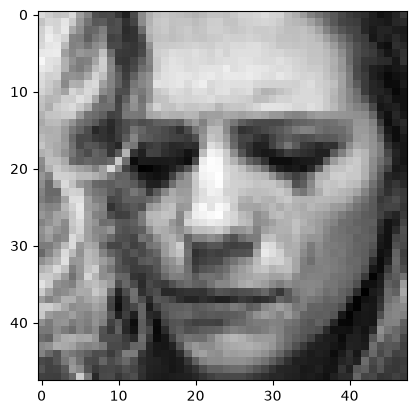

In [61]:
image = '/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images/train/sad/42.jpg'
print("original image is of sad")
image = train.loc[train["label"] == "sad", "image"].iloc[42]
img = ef(image)
pred = model.predict(img)
pred_label = label[pred.argmax()]
print("model prediction is ",pred_label)
plt.imshow(img.reshape(48,48),cmap='gray')

original image is of fear
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
model prediction is  fear


C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\keras_preprocessing\image\utils.py:107: UserWarning: grayscale is deprecated. Please use color_mode = "grayscale"
  warnings.warn('grayscale is deprecated. Please use '


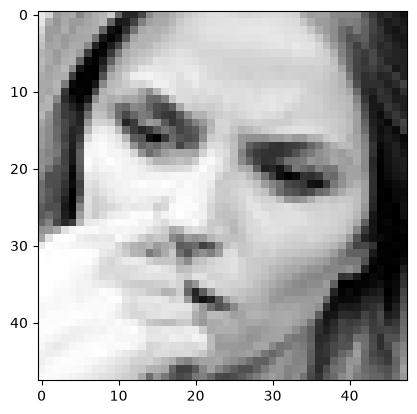

In [63]:
image = '/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images/train/fear/2.jpg'
print("original image is of fear")
# Use the actual dataset path already loaded in the notebook instead of the Linux path
image = os.path.join(TRAIN_DIR, "fear", "2.jpg")
if not os.path.exists(image):
    image = os.path.join(DATASET_PATH, "train", "fear", "2.jpg")
if not os.path.exists(image):
    raise FileNotFoundError(
        f"Fear image not found. Checked: {os.path.join(TRAIN_DIR, 'fear', '2.jpg')} and "
        f"{os.path.join(DATASET_PATH, 'train', 'fear', '2.jpg')}"
    )
img = ef(image)
pred = model.predict(img)
pred_label = label[pred.argmax()]
print("model prediction is ",pred_label)
plt.imshow(img.reshape(48,48),cmap='gray')

In [ ]:
image = '/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images/train/disgust/299.jpg'
print("original image is of disgust")
image = train.loc[train["label"] == "disgust", "image"].iloc[299]
img = ef(image)
pred = model.predict(img)
pred_label = label[pred.argmax()]
print("model prediction is ",pred_label)
plt.imshow(img.reshape(48,48),cmap='gray')

original image is of disgust


FileNotFoundError: [Errno 2] No such file or directory: '/root/.cache/kagglehub/datasets/jonathanoheix/face-expression-recognition-dataset/versions/1/images/train/disgust/299.jpg'

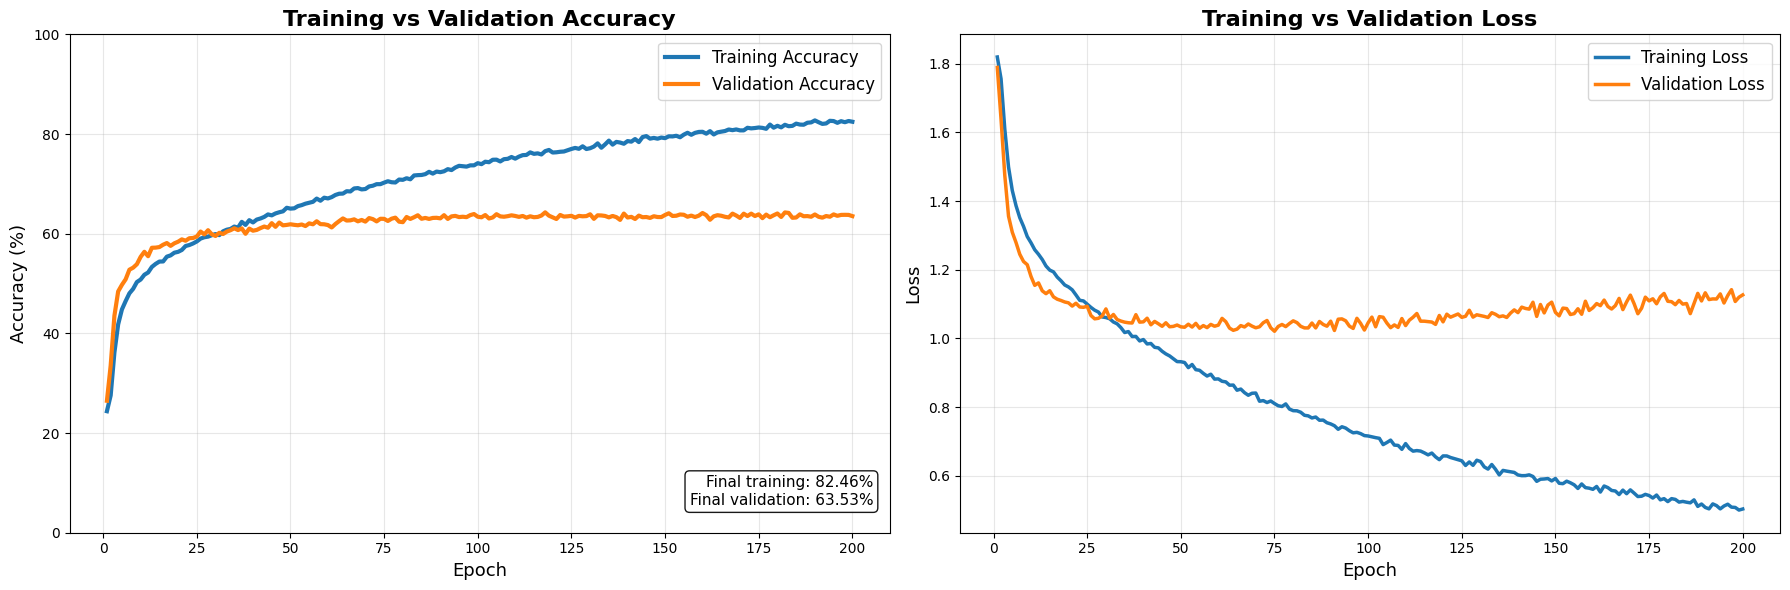

Best training accuracy: 82.73%
Best validation accuracy: 64.28%


In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure your training cell uses:
# history = model.fit(...)

hist = history.history
epochs = range(1, len(hist['accuracy']) + 1)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# ACCURACY — emphasize this graph
ax[0].plot(epochs, np.array(hist['accuracy']) * 100,
           linewidth=3, label='Training Accuracy')
if 'val_accuracy' in hist:
    ax[0].plot(epochs, np.array(hist['val_accuracy']) * 100,
               linewidth=3, label='Validation Accuracy')

ax[0].set_title('Training vs Validation Accuracy', fontsize=16, weight='bold')
ax[0].set_xlabel('Epoch', fontsize=13)
ax[0].set_ylabel('Accuracy (%)', fontsize=13)
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=12)
ax[0].set_ylim(0, 100)

# Add final accuracy labels
ax[0].text(0.98, 0.05,
           f"Final training: {hist['accuracy'][-1]*100:.2f}%"
           + (f"\nFinal validation: {hist['val_accuracy'][-1]*100:.2f}%"
              if 'val_accuracy' in hist else ""),
           transform=ax[0].transAxes, ha='right', va='bottom',
           fontsize=11, bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

# LOSS
ax[1].plot(epochs, hist['loss'], linewidth=2.5, label='Training Loss')
if 'val_loss' in hist:
    ax[1].plot(epochs, hist['val_loss'], linewidth=2.5,
               label='Validation Loss')

ax[1].set_title('Training vs Validation Loss', fontsize=16, weight='bold')
ax[1].set_xlabel('Epoch', fontsize=13)
ax[1].set_ylabel('Loss', fontsize=13)
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=12)

plt.tight_layout()
plt.show()

print(f"Best training accuracy: {max(hist['accuracy'])*100:.2f}%")
if 'val_accuracy' in hist:
    print(f"Best validation accuracy: {max(hist['val_accuracy'])*100:.2f}%")

In [2]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_names = ['angry', 'disgust', 'fear', 'happy',
               'neutral', 'sad', 'surprise']

y_true = np.argmax(y_test, axis=1)
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred, labels=range(7))

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    annot_kws={'size': 13}
)
plt.title('Confusion Matrix — Emotion Recognition', fontsize=17, weight='bold')
plt.xlabel('Predicted Emotion', fontsize=13)
plt.ylabel('Actual Emotion', fontsize=13)
plt.xticks(rotation=35)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(classification_report(
    y_true, y_pred,
    labels=range(7),
    target_names=class_names,
    zero_division=0
))

NameError: name 'np' is not defined

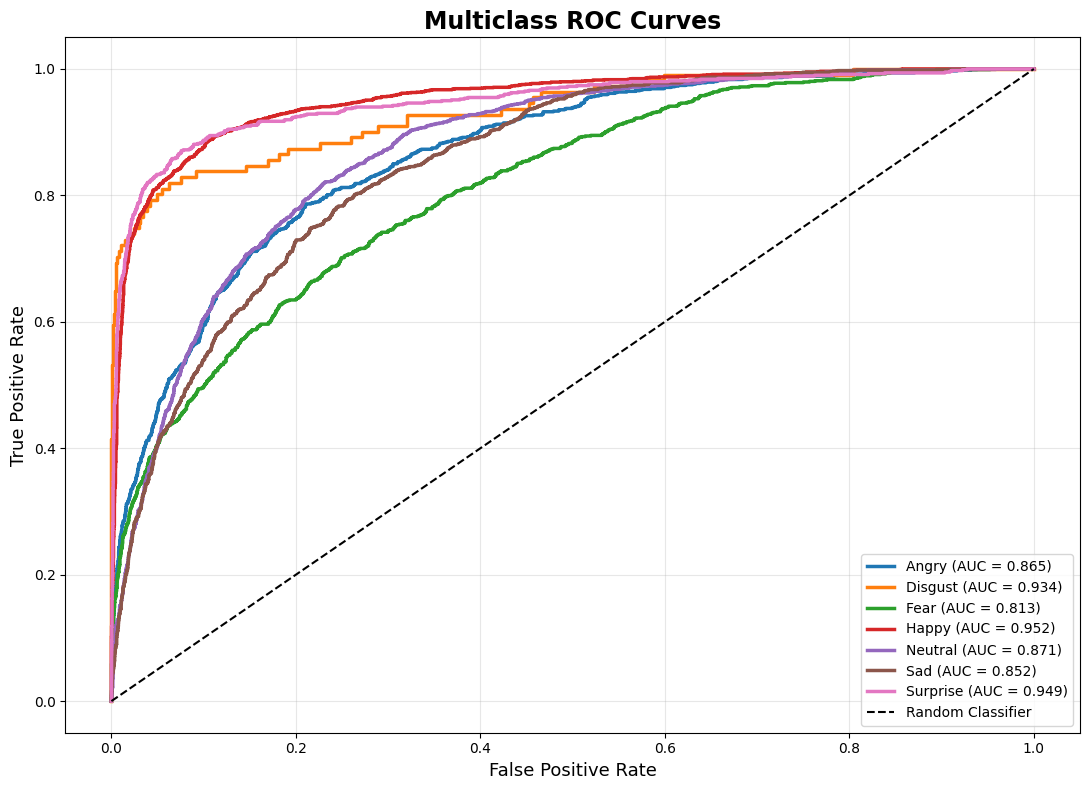

In [38]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_binary = label_binarize(y_true, classes=np.arange(7))

plt.figure(figsize=(11, 8))

for i, emotion in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_binary[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2.5,
             label=f'{emotion.title()} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title('Multiclass ROC Curves', fontsize=17, weight='bold')
plt.legend(fontsize=10, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
n = min(60, len(y_true))

plt.figure(figsize=(16, 6))
plt.plot(range(n), y_true[:n], 'o-', linewidth=2,
         markersize=5, label='Actual')
plt.plot(range(n), y_pred[:n], 'x--', linewidth=2,
         markersize=6, label='Predicted')

plt.yticks(range(7), class_names)
plt.xlabel('Test Image Index', fontsize=13)
plt.ylabel('Emotion', fontsize=13)
plt.title('Actual vs Predicted Emotions', fontsize=17, weight='bold')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'y_true' is not defined